In [ ]:
#Set config First (rerun as you restart the session)
import os, json, random, numpy as np, torch, shutil, importlib.util
from datetime import datetime
from transformers import BitsAndBytesConfig

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

CONFIG = {
    "model_id": "google/gemma-2b",
    "tokenizer": {"max_len": 256, "padding_side": "right", "pad_token_as_eos": True},
    "lora": {
        "r": 8, "alpha": 16, "dropout": 0.05,
        "target_modules": [
            "q_proj","k_proj","v_proj",
            "o_proj","gate_proj","up_proj","down_proj"
        ]
    },
    "optim": {
        "per_device_batch": 2,
        "grad_accum": 8,
        "lr": 2e-5,
        "epochs": 3,
        "fp16": True,
        "gradient_checkpointing": True
    },
    "seeds": {"main": 42}
}
set_seed(CONFIG["seeds"]["main"])

STAMP = datetime.utcnow().strftime("%Y%m%d-%H%M%S")
EXP_ROOT = os.path.join("runs", f"cot_runs_{STAMP}")
os.makedirs(EXP_ROOT, exist_ok=True)

with open(os.path.join(EXP_ROOT, "CONFIG.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Experiment root:", EXP_ROOT)


import os
from huggingface_hub import login
tok = os.getenv("HF_TOKEN")
if tok:
    login(token=tok)


****GSM8K — seed 42 CE baseline (train/val from ranked JSON), save all artifacts****

In [ ]:
import os, json, re
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

if "CONFIG" not in globals():
    CONFIG = {
        "model_id": "google/gemma-2b",
        "tokenizer": {"max_len": 256, "padding_side": "right", "pad_token_as_eos": True},
        "lora": {"r": 8, "alpha": 16, "dropout": 0.05,
                 "target_modules": ["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"]},
        "optim": {"per_device_batch": 2, "grad_accum": 8, "lr": 2e-5, "epochs": 3,
                  "fp16": True, "gradient_checkpointing": True}
    }
if "EXP_ROOT" not in globals():
    EXP_ROOT = os.path.join("runs", "cot_runs_single")

def choose_quant():
    try:
        import triton  # noqa
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    except Exception:
        return BitsAndBytesConfig(load_in_8bit=True)

bnb = choose_quant()

data_path = os.getenv("GSM8K_RANKED_JSON", "./data/gsm8k_gemini_level4_ranked.json")
assert os.path.exists(data_path), f"Missing dataset at {data_path}"

out_dir  = os.path.join(EXP_ROOT, "gsm8k")
ckpt_dir = os.path.join(out_dir, "checkpoints")
final_dir = os.path.join(out_dir, "final_adapter")
os.makedirs(ckpt_dir, exist_ok=True); os.makedirs(final_dir, exist_ok=True)

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_id"], use_fast=True)
if CONFIG["tokenizer"].get("pad_token_as_eos", True) and tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = CONFIG["tokenizer"].get("padding_side", "right")

model = AutoModelForCausalLM.from_pretrained(
    CONFIG["model_id"], quantization_config=bnb, device_map="auto"
)
model = prepare_model_for_kbit_training(model)
lcfg = LoraConfig(
    r=CONFIG["lora"]["r"], lora_alpha=CONFIG["lora"]["alpha"], lora_dropout=CONFIG["lora"]["dropout"],
    bias="none", task_type="CAUSAL_LM", target_modules=CONFIG["lora"]["target_modules"]
)
model = get_peft_model(model, lcfg)
if CONFIG["optim"].get("gradient_checkpointing", True):
    model.gradient_checkpointing_enable()
model.config.use_cache = False

NUM_RE = re.compile(r"(?:####\s*|The answer is\s*)(-?\d+)", re.IGNORECASE)

def read_json(path):
    with open(path) as f: return json.load(f)

def build_splits(path, split_ratio=0.9):
    data = read_json(path)
    rows = []
    for ex in data:
        instr = (ex.get("instruction") or "").strip()
        out   = (ex.get("output") or "").strip()
        if not instr or not out:
            continue
        m = NUM_RE.findall(out); gold = m[-1] if m else ""
        rows.append({"prompt": instr, "target": out, "gold": gold})
    n = len(rows); k = int(n * split_ratio)
    return Dataset.from_list(rows[:k]), Dataset.from_list(rows[k:])

def preprocess_fullseq(batch, tok, max_len):
    texts = [p + " " + t for p, t in zip(batch["prompt"], batch["target"])]
    enc = tok(texts, truncation=True, max_length=max_len, padding="max_length")
    enc["labels"] = enc["input_ids"].copy()
    return enc

train_ds, val_ds = build_splits(data_path, split_ratio=0.9)
train_tok = train_ds.map(lambda b: preprocess_fullseq(b, tokenizer, CONFIG["tokenizer"]["max_len"]),
                         batched=True, remove_columns=train_ds.column_names)
val_tok   = val_ds.map(lambda b: preprocess_fullseq(b, tokenizer, CONFIG["tokenizer"]["max_len"]),
                       batched=True, remove_columns=val_ds.column_names)

args = TrainingArguments(
    output_dir=ckpt_dir,
    per_device_train_batch_size=CONFIG["optim"]["per_device_batch"],
    per_device_eval_batch_size=CONFIG["optim"]["per_device_batch"],
    gradient_accumulation_steps=CONFIG["optim"]["grad_accum"],
    learning_rate=CONFIG["optim"]["lr"],
    num_train_epochs=CONFIG["optim"]["epochs"],
    eval_strategy="epoch",
    logging_steps=50,
    save_strategy="epoch",
    save_total_limit=3,
    fp16=CONFIG["optim"]["fp16"],
    report_to="none",
    remove_unused_columns=False,
    load_best_model_at_end=True,
)

trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok)
trainer.train()
metrics = trainer.evaluate()

trainer.save_model(final_dir)
tokenizer.save_pretrained(os.path.join(final_dir, "tokenizer"))
with open(os.path.join(out_dir, "metrics_last_eval.json"), "w") as f:
    json.dump(metrics, f, indent=2)
with open(os.path.join(out_dir, "log_history.json"), "w") as f:
    json.dump(trainer.state.log_history, f, indent=2)
print("Saved to:", out_dir)


***CSQA — Seed 42 CE baseline (train/val from ranked JSON), save all artifacts***

In [ ]:
import os, json, re, hashlib
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

if "CONFIG" not in globals():
    CONFIG = {
        "model_id": "google/gemma-2b",
        "tokenizer": {"max_len": 256, "padding_side": "right", "pad_token_as_eos": True},
        "lora": {"r": 8, "alpha": 16, "dropout": 0.05,
                 "target_modules": ["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"]},
        "optim": {"per_device_batch": 2, "grad_accum": 8, "lr": 2e-5, "epochs": 3,
                  "fp16": True, "gradient_checkpointing": True}
    }
if "EXP_ROOT" not in globals():
    EXP_ROOT = os.path.join("runs", "cot_runs_single")

def choose_quant():
    try:
        import triton  # noqa
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    except Exception:
        return BitsAndBytesConfig(load_in_8bit=True)

bnb = choose_quant()

data_path = os.getenv("CSQA_RANKED_JSON", "./data/csqa_gemini_level3_ranked.json")
assert os.path.exists(data_path), f"Missing dataset at {data_path}"

out_dir   = os.path.join(EXP_ROOT, "csqa")
ckpt_dir  = os.path.join(out_dir, "checkpoints")
final_dir = os.path.join(out_dir, "final_adapter")
os.makedirs(ckpt_dir, exist_ok=True); os.makedirs(final_dir, exist_ok=True)

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_id"], use_fast=True)
if CONFIG["tokenizer"].get("pad_token_as_eos", True) and tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = CONFIG["tokenizer"].get("padding_side", "right")

model = AutoModelForCausalLM.from_pretrained(CONFIG["model_id"], quantization_config=bnb, device_map="auto")
model = prepare_model_for_kbit_training(model)
lcfg = LoraConfig(
    r=CONFIG["lora"]["r"], lora_alpha=CONFIG["lora"]["alpha"], lora_dropout=CONFIG["lora"]["dropout"],
    bias="none", task_type="CAUSAL_LM", target_modules=CONFIG["lora"]["target_modules"]
)
model = get_peft_model(model, lcfg)
if CONFIG["optim"].get("gradient_checkpointing", True):
    model.gradient_checkpointing_enable()
model.config.use_cache = False

LETTER_RE = re.compile(r"answer is\s*([A-E])", re.IGNORECASE)

def read_json(path):
    with open(path, "r") as f: return json.load(f)

def build_splits(path, split_ratio=0.9):
    data = read_json(path)
    rows = []
    for ex in data:
        instr = (ex.get("instruction") or "").strip()
        out   = (ex.get("output") or "").strip()
        if not instr or not out:
            continue
        m = LETTER_RE.findall(out); gold = m[-1].upper() if m else ""
        rows.append({"prompt": instr, "target": out, "gold": gold})
    n = len(rows); k = int(n * split_ratio)
    return Dataset.from_list(rows[:k]), Dataset.from_list(rows[k:])

def preprocess_fullseq(batch, tok, max_len):
    texts = [p + " " + t for p, t in zip(batch["prompt"], batch["target"])]
    enc = tok(texts, truncation=True, max_length=max_len, padding="max_length")
    enc["labels"] = enc["input_ids"].copy()
    return enc

train_ds, val_ds = build_splits(data_path, split_ratio=0.9)
train_tok = train_ds.map(lambda b: preprocess_fullseq(b, tokenizer, CONFIG["tokenizer"]["max_len"]),
                         batched=True, remove_columns=train_ds.column_names)
val_tok   = val_ds.map(lambda b: preprocess_fullseq(b, tokenizer, CONFIG["tokenizer"]["max_len"]),
                       batched=True, remove_columns=val_ds.column_names)

args = TrainingArguments(
    output_dir=ckpt_dir,
    per_device_train_batch_size=CONFIG["optim"]["per_device_batch"],
    per_device_eval_batch_size=CONFIG["optim"]["per_device_batch"],
    gradient_accumulation_steps=CONFIG["optim"]["grad_accum"],
    learning_rate=CONFIG["optim"]["lr"],
    num_train_epochs=CONFIG["optim"]["epochs"],
    eval_strategy="epoch",
    logging_steps=50,
    save_strategy="epoch",
    save_total_limit=3,
    fp16=CONFIG["optim"]["fp16"],
    report_to="none",
    remove_unused_columns=False,
    load_best_model_at_end=True,
)

trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok)
trainer.train()
metrics = trainer.evaluate()

trainer.save_model(final_dir)
tokenizer.save_pretrained(os.path.join(final_dir, "tokenizer"))
with open(os.path.join(out_dir, "metrics_last_eval.json"), "w") as f: json.dump(metrics, f, indent=2)
with open(os.path.join(out_dir, "log_history.json"), "w") as f: json.dump(trainer.state.log_history, f, indent=2)

with open(os.path.join(out_dir, "CONFIG.json"), "w") as f: json.dump(CONFIG, f, indent=2)

def hash_ids(ds_df):
    s = "|".join(ds_df["prompt"])
    import pandas as pd
    return hashlib.sha256(s.encode()).hexdigest()

split_info = {
    "train_len": len(train_ds),
    "val_len": len(val_ds),
    "train_hash": hash_ids(train_ds.to_pandas()),
    "val_hash":   hash_ids(val_ds.to_pandas())
}
with open(os.path.join(out_dir, "SPLIT_INFO.json"), "w") as f: json.dump(split_info, f, indent=2)
print("Saved artifacts to:", out_dir)


**DESIGNED LOSS for 3 seeds** 

**Gemma-2B + QLoRA + SWCE, 3 seeds**

In [ ]:
# TRAIN SWCE - GSM8K FOR 3 SEEDS
import os, re, json, random, gc, hashlib
import numpy as np
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# Reuse CONFIG and EXP_ROOT from starter cell
if "CONFIG" not in globals():
    raise RuntimeError("Run the starter config cell first.")

if "EXP_ROOT" not in globals():
    EXP_ROOT = os.path.join("runs", "cot_runs_single")

def choose_quant():
    try:
        import triton  # noqa
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    except Exception:
        return BitsAndBytesConfig(load_in_8bit=True)

bnb = choose_quant()

data_path = os.getenv("GSM8K_RANKED_JSON", "./data/gsm8k_gemini_level4_ranked.json")
assert os.path.exists(data_path), f"Missing dataset at {data_path}"

out_root = os.path.join(EXP_ROOT, "gsm8k_swce")
os.makedirs(out_root, exist_ok=True)

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_id"], use_fast=True)
if CONFIG["tokenizer"].get("pad_token_as_eos", True) and tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = CONFIG["tokenizer"].get("padding_side", "left")
MAX_LEN = CONFIG["tokenizer"]["max_len"]

NUM_RE = re.compile(r"(?:####\s*|The answer is\s*)(-?\d+)", re.IGNORECASE)
W_STEP, W_ANS = 1.25, 1.50

def read_json(path):
    with open(path) as f: return json.load(f)

def build_splits(path, split_ratio=0.9):
    data = read_json(path)
    rows = []
    for ex in data:
        instr = (ex.get("instruction") or "").strip()
        out   = (ex.get("output") or "").strip()
        if not instr or not out: continue
        m = NUM_RE.findall(out); gold = m[-1] if m else ""
        rows.append({"prompt": instr, "target": out, "gold": gold})
    n = len(rows); k = int(n * split_ratio)
    return Dataset.from_list(rows[:k]), Dataset.from_list(rows[k:])

def features_swce(batch):
    input_ids_list, attn_list, labels_list, weights_list = [], [], [], []
    for p, t in zip(batch["prompt"], batch["target"]):
        tok_p = tokenizer(p, add_special_tokens=False)
        tok_t = tokenizer(t, add_special_tokens=False, return_offsets_mapping=True)
        inp   = tok_p["input_ids"] + tok_t["input_ids"]
        attn  = [1]*len(inp)
        labels= [-100]*len(tok_p["input_ids"]) + tok_t["input_ids"]

        m = NUM_RE.search(t); ans_span = m.span() if m else None
        tgt_w = []
        for (start,end) in tok_t["offset_mapping"]:
            if ans_span and not (end <= ans_span[0] or start >= ans_span[1]):
                tgt_w.append(W_ANS)
            else:
                tgt_w.append(W_STEP)
        weights = [0.0]*len(tok_p["input_ids"]) + tgt_w

        if len(inp) > MAX_LEN:
            inp, attn, labels, weights = inp[:MAX_LEN], attn[:MAX_LEN], labels[:MAX_LEN], weights[:MAX_LEN]
        else:
            pad = MAX_LEN - len(inp)
            inp += [tokenizer.pad_token_id]*pad
            attn += [0]*pad
            labels += [-100]*pad
            weights += [0.0]*pad

        lbl_mask = np.array([1.0 if t!=-100 else 0.0 for t in labels], dtype=float)
        w = np.array(weights, dtype=float)
        denom = float((w*lbl_mask).sum())
        if denom > 0:
            w *= (lbl_mask.sum()/denom)
        weights = w.tolist()

        input_ids_list.append(inp); attn_list.append(attn)
        labels_list.append(labels); weights_list.append(weights)

    return {"input_ids": input_ids_list, "attention_mask": attn_list,
            "labels": labels_list, "weights": weights_list}

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False):
        labels  = inputs.pop("labels")
        weights = inputs.pop("weights")
        outputs = model(**inputs)
        logits  = outputs.logits
        shift_logits  = logits[:, :-1, :].contiguous()
        shift_labels  = labels[:, 1:].contiguous()
        shift_weights = weights[:, 1:].contiguous()
        loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="none")
        loss_flat = loss_fn(shift_logits.view(-1, shift_logits.size(-1)),
                            shift_labels.view(-1))
        loss = loss_flat.view(shift_labels.size())
        mask = (shift_labels != -100).float()
        num  = (loss * shift_weights * mask).sum(dim=1)
        den  = (shift_weights * mask).sum(dim=1).clamp_min(1e-8)
        loss = (num/den).mean()
        return (loss, outputs) if return_outputs else loss

def run_swce_gsm8k(seed: int):
    print(f"\n  GSM8K | SWCE | seed={seed} ")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    train_ds, val_ds = build_splits(data_path, split_ratio=0.9)
    train_tok = train_ds.map(lambda b: features_swce(b), batched=True, remove_columns=train_ds.column_names)
    val_tok   = val_ds.map(lambda b: features_swce(b),   batched=True, remove_columns=val_ds.column_names)

    base = AutoModelForCausalLM.from_pretrained(CONFIG["model_id"], quantization_config=bnb, device_map="auto")
    base = prepare_model_for_kbit_training(base)
    lcfg = LoraConfig(
        r=CONFIG["lora"]["r"], lora_alpha=CONFIG["lora"]["alpha"], lora_dropout=CONFIG["lora"]["dropout"],
        bias="none", task_type="CAUSAL_LM", target_modules=CONFIG["lora"]["target_modules"],
    )
    model = get_peft_model(base, lcfg)
    if CONFIG["optim"].get("gradient_checkpointing", True):
        model.gradient_checkpointing_enable()
    model.config.use_cache = False

    dout = os.path.join(out_root, f"seed{seed}")
    ckpt_dir  = os.path.join(dout, "checkpoints")
    final_dir = os.path.join(dout, "final_adapter")
    os.makedirs(ckpt_dir, exist_ok=True); os.makedirs(final_dir, exist_ok=True)

    args = TrainingArguments(
        output_dir=ckpt_dir,
        per_device_train_batch_size=CONFIG["optim"]["per_device_batch"],
        per_device_eval_batch_size=CONFIG["optim"]["per_device_batch"],
        gradient_accumulation_steps=CONFIG["optim"]["grad_accum"],
        learning_rate=CONFIG["optim"]["lr"],
        num_train_epochs=CONFIG["optim"]["epochs"],
        evaluation_strategy="epoch",
        logging_steps=50,
        save_strategy="epoch",
        save_total_limit=3,
        fp16=CONFIG["optim"]["fp16"],
        report_to="none",
        remove_unused_columns=False,
        load_best_model_at_end=True,
        seed=seed,
    )

    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_tok,
                              eval_dataset=val_tok, tokenizer=tokenizer)
    trainer.train()
    metrics = trainer.evaluate()

    trainer.save_model(final_dir)
    tokenizer.save_pretrained(os.path.join(final_dir, "tokenizer"))
    with open(os.path.join(dout, "metrics_last_eval.json"), "w") as f: json.dump(metrics, f, indent=2)
    with open(os.path.join(dout, "log_history.json"), "w") as f: json.dump(trainer.state.log_history, f, indent=2)
    with open(os.path.join(dout, "RUN_MANIFEST.json"), "w") as f:
        json.dump({"stage":"FULL","loss":"SWCE","weights":{"w_step":W_STEP,"w_ans":W_ANS},
                   "seed":seed,"config":CONFIG,"dataset":"gsm8k","json_path":data_path,
                   "split_ratio":0.9,"max_len":MAX_LEN}, f, indent=2)
    print("Saved artifacts to:", dout)

    del trainer, model, base; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

SEEDS = CONFIG.get("seeds", {}).get("full", [41, 42, 43])
for s in SEEDS:
    run_swce_gsm8k(s)

print("Done: GSM8K SWCE runs stored in", out_root)


In [ ]:
# TRAIN SWCE - CSQA FOR 3 SEEDS
import os, re, json, random, gc
import numpy as np
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

if "CONFIG" not in globals():
    raise RuntimeError("Run the starter config cell first.")

if "EXP_ROOT" not in globals():
    EXP_ROOT = os.path.join("runs", "cot_runs_single")

def choose_quant():
    try:
        import triton  # noqa
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    except Exception:
        return BitsAndBytesConfig(load_in_8bit=True)

bnb = choose_quant()

data_path = os.getenv("CSQA_RANKED_JSON", "./data/csqa_gemini_level3_ranked.json")
assert os.path.exists(data_path), f"Missing dataset at {data_path}"

out_root = os.path.join(EXP_ROOT, "csqa_swce")
os.makedirs(out_root, exist_ok=True)

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_id"], use_fast=True)
if CONFIG["tokenizer"].get("pad_token_as_eos", True) and tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = CONFIG["tokenizer"].get("padding_side", "left")
MAX_LEN = CONFIG["tokenizer"]["max_len"]

ANS_RE = re.compile(r"(?:Final\s*Answer|Answer)\s*[:\-]\s*([A-E])", re.IGNORECASE)
W_STEP, W_ANS = 1.25, 1.50

def read_json(path):
    with open(path) as f: return json.load(f)

def build_splits(path, split_ratio=0.9):
    data = read_json(path)
    rows = []
    for ex in data:
        instr = (ex.get("instruction") or "").strip()
        out   = (ex.get("output") or "").strip()
        if not instr or not out:
            continue
        m = ANS_RE.search(out)
        gold = m.group(1).upper() if m else ""
        rows.append({"prompt": instr, "target": out, "gold": gold})
    n = len(rows); k = int(n * split_ratio)
    return Dataset.from_list(rows[:k]), Dataset.from_list(rows[k:])

def features_swce(batch):
    input_ids_list, attn_list, labels_list, weights_list = [], [], [], []
    for p, t in zip(batch["prompt"], batch["target"]):
        tok_p = tokenizer(p, add_special_tokens=False)
        tok_t = tokenizer(t, add_special_tokens=False, return_offsets_mapping=True)
        inp   = tok_p["input_ids"] + tok_t["input_ids"]
        attn  = [1]*len(inp)
        labels= [-100]*len(tok_p["input_ids"]) + tok_t["input_ids"]

        m = ANS_RE.search(t)
        if m:
            ans_start, ans_end = m.span(1)
        else:
            ans_start, ans_end = max(0, len(t)-20), len(t)

        tgt_w = []
        for (start,end) in tok_t["offset_mapping"]:
            if not (end <= ans_start or start >= ans_end):
                tgt_w.append(W_ANS)
            else:
                tgt_w.append(W_STEP)
        weights = [0.0]*len(tok_p["input_ids"]) + tgt_w

        if len(inp) > MAX_LEN:
            inp, attn, labels, weights = inp[:MAX_LEN], attn[:MAX_LEN], labels[:MAX_LEN], weights[:MAX_LEN]
        else:
            pad = MAX_LEN - len(inp)
            inp += [tokenizer.pad_token_id]*pad
            attn += [0]*pad
            labels += [-100]*pad
            weights += [0.0]*pad

        lbl_mask = np.array([1.0 if t!=-100 else 0.0 for t in labels], dtype=float)
        w = np.array(weights, dtype=float)
        denom = float((w*lbl_mask).sum())
        if denom > 0:
            w *= (lbl_mask.sum()/denom)
        weights = w.tolist()

        input_ids_list.append(inp); attn_list.append(attn)
        labels_list.append(labels); weights_list.append(weights)

    return {"input_ids": input_ids_list, "attention_mask": attn_list,
            "labels": labels_list, "weights": weights_list}

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False):
        labels  = inputs.pop("labels")
        weights = inputs.pop("weights")
        outputs = model(**inputs)
        logits  = outputs.logits
        shift_logits  = logits[:, :-1, :].contiguous()
        shift_labels  = labels[:, 1:].contiguous()
        shift_weights = weights[:, 1:].contiguous()
        loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="none")
        loss_flat = loss_fn(shift_logits.view(-1, shift_logits.size(-1)),
                            shift_labels.view(-1))
        loss = loss_flat.view(shift_labels.size())
        mask = (shift_labels != -100).float()
        num  = (loss * shift_weights * mask).sum(dim=1)
        den  = (shift_weights * mask).sum(dim=1).clamp_min(1e-8)
        loss = (num/den).mean()
        return (loss, outputs) if return_outputs else loss

def run_swce_csqa(seed: int):
    print(f"\nCSQA | SWCE | seed={seed}")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    train_ds, val_ds = build_splits(data_path, split_ratio=0.9)
    train_tok = train_ds.map(lambda b: features_swce(b), batched=True, remove_columns=train_ds.column_names)
    val_tok   = val_ds.map(lambda b: features_swce(b),   batched=True, remove_columns=val_ds.column_names)

    base = AutoModelForCausalLM.from_pretrained(CONFIG["model_id"], quantization_config=bnb, device_map="auto")
    base = prepare_model_for_kbit_training(base)
    lcfg = LoraConfig(
        r=CONFIG["lora"]["r"], lora_alpha=CONFIG["lora"]["alpha"], lora_dropout=CONFIG["lora"]["dropout"],
        bias="none", task_type="CAUSAL_LM", target_modules=CONFIG["lora"]["target_modules"],
    )
    model = get_peft_model(base, lcfg)
    if CONFIG["optim"].get("gradient_checkpointing", True):
        model.gradient_checkpointing_enable()
    model.config.use_cache = False

    dout = os.path.join(out_root, f"seed{seed}")
    ckpt_dir  = os.path.join(dout, "checkpoints")
    final_dir = os.path.join(dout, "final_adapter")
    os.makedirs(ckpt_dir, exist_ok=True); os.makedirs(final_dir, exist_ok=True)

    args = TrainingArguments(
        output_dir=ckpt_dir,
        per_device_train_batch_size=CONFIG["optim"]["per_device_batch"],
        per_device_eval_batch_size=CONFIG["optim"]["per_device_batch"],
        gradient_accumulation_steps=CONFIG["optim"]["grad_accum"],
        learning_rate=CONFIG["optim"]["lr"],
        num_train_epochs=CONFIG["optim"]["epochs"],
        evaluation_strategy="epoch",
        logging_steps=50,
        save_strategy="epoch",
        save_total_limit=3,
        fp16=CONFIG["optim"]["fp16"],
        report_to="none",
        remove_unused_columns=False,
        load_best_model_at_end=True,
        seed=seed,
    )

    trainer = WeightedTrainer(model=model, args=args,
                              train_dataset=train_tok, eval_dataset=val_tok,
                              tokenizer=tokenizer)
    trainer.train()
    metrics = trainer.evaluate()

    trainer.save_model(final_dir)
    tokenizer.save_pretrained(os.path.join(final_dir, "tokenizer"))
    with open(os.path.join(dout, "metrics_last_eval.json"), "w") as f: json.dump(metrics, f, indent=2)
    with open(os.path.join(dout, "log_history.json"), "w") as f: json.dump(trainer.state.log_history, f, indent=2)
    with open(os.path.join(dout, "RUN_MANIFEST.json"), "w") as f:
        json.dump({"stage":"FULL","loss":"SWCE","weights":{"w_step":W_STEP,"w_ans":W_ANS},
                   "seed":seed,"config":CONFIG,"dataset":"csqa","json_path":data_path,
                   "split_ratio":0.9,"max_len":MAX_LEN}, f, indent=2)
    print("Saved artifacts to:", dout)

    del trainer, model, base; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

SEEDS = CONFIG.get("seeds", {}).get("full", [41, 42, 43])
for s in SEEDS:
    run_swce_csqa(s)

print("Done: CSQA SWCE runs stored in", out_root)


**Evaluation**

**step1.baseline CE**

In [ ]:
import os, json, random, numpy as np, torch, importlib.util
from datetime import datetime
from transformers import BitsAndBytesConfig

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

ADAPTER_DIR = os.getenv("ADAPTER_DIR", "./runs/gsm8k/final_adapter")  # change per eval
cfg_path = os.path.join(os.path.dirname(ADAPTER_DIR), "CONFIG.json")
if os.path.isfile(cfg_path):
    with open(cfg_path) as f:
        CONFIG = json.load(f)
else:
    
    CONFIG = {
        "model_id": "google/gemma-2b",
        "tokenizer": {
            "max_len": 1024,          # match training to avoid truncation mismatch
            "pad_token_as_eos": True,
            "padding_side": "left"    # left-padding is typical for generation
        },
        "seeds": {"main": 42}
    }

# Quantization
_bnb = importlib.util.find_spec("bitsandbytes") is not None
_triton = importlib.util.find_spec("triton") is not None
if _bnb and _triton:
    QUANT = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
elif _bnb:
    QUANT = BitsAndBytesConfig(load_in_8bit=True)
else:
    QUANT = None  # fallback: full precision (fp16/bf16 depending on platform)

# Where to save eval artifacts
EXP_ROOT = os.getenv("EXP_ROOT", "./eval_runs")
os.makedirs(EXP_ROOT, exist_ok=True)

set_seed(CONFIG.get("seeds", {}).get("main", 42))

print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
print("Model:", CONFIG["model_id"])
print("Tokenizer:", CONFIG["tokenizer"])
print("Quantization:", "4-bit" if (_bnb and _triton) else "8-bit" if _bnb else "fp16/bf16")


In [ ]:
#BASELINE GSM8K EVALUATION (Gemma-2B + LoRA adapter)
import os, re, json, math
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig, BitsAndBytesConfig
from peft import PeftModel
import matplotlib.pyplot as plt

SEED = 42
MAX_NEW = 128
BATCH = 16
MAX_LEN = int(CONFIG.get("tokenizer", {}).get("max_len", 1024))

BASE_MODEL_ID = CONFIG["model_id"]
ADAPTER_DIR = "./runs/gsm8k/final_adapter"
OUT_DIR = f"./eval_gsm8k_seed{SEED}_CE"
os.makedirs(OUT_DIR, exist_ok=True)

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, use_fast=True)
if CONFIG.get("tokenizer", {}).get("pad_token_as_eos", False) and tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
base = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID,
    quantization_config=bnb, device_map="auto", low_cpu_mem_usage=True)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
model.eval()

ds = load_dataset("gsm8k", "main")
test = ds["test"]

FIRST_ANS_RE = re.compile(r"(?i)\bThe answer is\s*(-?\d+)\b")
HASH_RE = re.compile(r"(?:^|\n)####\s*(-?\d+)\b")

def prompt(q: str) -> str:
    return (
        "You are a math teacher. Solve step by step.\n"
        "Finish with a single line: 'The answer is <number>'.\n\n"
        f"Q: {q}\nA:"
    )

def truncate_after_first_answer(text: str) -> str:
    if not isinstance(text, str): return ""
    m = FIRST_ANS_RE.search(text)
    if m: return text[:m.end()]
    m2 = HASH_RE.search(text)
    if m2: return text[:m2.end()]
    i = text.find("\nQ:")
    return text if i < 0 else text[:i]

def extract_first_answer_num(text: str):
    t = truncate_after_first_answer(text)
    m = FIRST_ANS_RE.search(t)
    if m: return m.group(1)
    m2 = HASH_RE.search(t)
    return m2.group(1) if m2 else None

@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(model.device)
    out = model.generate(**enc, do_sample=False,
                         max_new_tokens=MAX_NEW,
                         eos_token_id=tok.eos_token_id,
                         pad_token_id=tok.pad_token_id)
    return tok.batch_decode(out, skip_special_tokens=True)

rows = []
for i in range(0, len(test), BATCH):
    batch = test.select(range(i, min(i+BATCH, len(test))))
    golds = []
    for ex in batch:
        m = FIRST_ANS_RE.findall(ex["answer"]) or HASH_RE.findall(ex["answer"])
        golds.append(m[0] if m else None)

    outs = generate_batch([prompt(q) for q in batch["question"]])

    for ex, pt_full, g in zip(batch, outs, golds):
        pt = truncate_after_first_answer(pt_full)
        pv = extract_first_answer_num(pt)
        rows.append({
            "id": ex.get("id"),
            "question": ex["question"],
            "gold_text": ex["answer"], "gold_num": g,
            "pred_text": pt, "pred_text_full": pt_full,
            "pred_num": pv,
            "correct": int(pv is not None and g is not None and pv == g)
        })
    print(f"Evaluated {i+len(batch)}/{len(test)}")

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
with open(os.path.join(OUT_DIR, "predictions.json"), "w") as f: json.dump(rows, f, indent=2)

N = len(df)
k = int(df["correct"].sum())
p = k / max(1, N)
se = (p * (1 - p) / max(1, N)) ** 0.5
lo, hi = max(0.0, p - 1.96*se), min(1.0, p + 1.96*se)

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump({"seed": SEED, "N": N, "correct": k, "EM": p,
               "CI95_low": lo, "CI95_high": hi}, f, indent=2)

plt.figure()
plt.bar(["EM"], [p])
plt.errorbar(["EM"], [p], yerr=[[p - lo], [hi - p]], fmt='o')
plt.ylim(0, 1)
plt.title(f"GSM8K Test EM (95% CI) — CE seed {SEED}")
plt.ylabel("Exact Match")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "em_ci.png"), dpi=150)
plt.show()

print(f"GSM8K CE seed {SEED}: EM={p:.4f}, 95% CI=({lo:.4f}, {hi:.4f}), N={N}")


In [ ]:
# CSQA Baseline Evaluation (Gemma-2B + LoRA adapter)
import os, re, json, math
import pandas as pd, numpy as np, torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig, BitsAndBytesConfig
from peft import PeftModel

SEED = 42
MAX_NEW = 64
BATCH = 16
MAX_LEN = 1024

BASE_MODEL_ID = CONFIG["model_id"]
ADAPTER_DIR = "./runs/csqa/final_adapter"   # <-- adjust if needed
OUT_DIR = f"./eval_csqa_seed{SEED}_CE"
os.makedirs(OUT_DIR, exist_ok=True)

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, use_fast=True)
if CONFIG.get("tokenizer", {}).get("pad_token_as_eos", False) and tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"

# Quantization
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID, quantization_config=bnb,
    device_map="auto", low_cpu_mem_usage=True
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR); model.eval()

csqa = load_dataset("tau/commonsense_qa")["validation"]

def csqa_prompt(ex):
    opts = "\n".join([f"{l}. {t}" for l, t in zip(ex["choices"]["label"], ex["choices"]["text"])])
    return f"Q: {ex['question']}\n{opts}\nAnswer:"

ANSWER_RE = re.compile(r"(?i)\banswer\s*[:\-]?\s*\(?\s*([A-E])\s*\)?")

def truncate_after_answer(text: str) -> str:
    if not isinstance(text, str): return ""
    m = ANSWER_RE.search(text)
    return text[:m.end()] if m else text

@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(model.device)
    out = model.generate(**enc, do_sample=False, max_new_tokens=MAX_NEW,
                         eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)
    return tok.batch_decode(out, skip_special_tokens=True)

rows = []
for i in range(0, len(csqa), BATCH):
    batch = csqa.select(range(i, min(i+BATCH, len(csqa))))
    outs = generate_batch([csqa_prompt(ex) for ex in batch])
    for ex, pt in zip(batch, outs):
        pt_trunc = truncate_after_answer(pt)
        rows.append({
            "id": ex.get("id"),
            "question": ex["question"],
            "choices": ex["choices"],
            "gold": ex["answerKey"],
            "pred_text": pt_trunc,
            "pred_text_full": pt
        })
    print(f"Evaluated {i+len(batch)}/{len(csqa)}")

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
with open(os.path.join(OUT_DIR, "predictions.json"), "w") as f: json.dump(rows, f, indent=2)

def extract_letter(s):
    if not isinstance(s, str): return None
    m = ANSWER_RE.search(s)
    return m.group(1).upper() if m else None

df["pred_letter"] = df["pred_text"].apply(extract_letter)
df["gold_letter"] = df["gold"].str.upper().str[0]
df["correct"] = df["pred_letter"] == df["gold_letter"]

N = len(df)
k = int(df["correct"].sum())
p = k / max(1, N)
se = math.sqrt(p * (1 - p) / max(1, N))
ci_low, ci_high = max(0.0, p - 1.96*se), min(1.0, p + 1.96*se)

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump({"seed": SEED, "N": N, "correct": k, "ACC": p,
               "CI95_low": ci_low, "CI95_high": ci_high}, f, indent=2)

with open(os.path.join(OUT_DIR, "EVAL_INFO.json"), "w") as f:
    json.dump({
        "dataset": "tau/commonsense_qa", "split": "validation",
        "base_model": BASE_MODEL_ID, "adapter_dir": ADAPTER_DIR,
        "decoding": {"strategy": "greedy", "max_new_tokens": MAX_NEW},
        "seed": SEED, "max_len": MAX_LEN,
        "quantization": "4bit"
    }, f, indent=2)

print(f"CSQA CE seed {SEED}: ACC={p:.4f}, 95% CI=({ci_low:.4f},{ci_high:.4f}), N={N}")


**step2. WEIGHTED LOSS EVALUATION**

In [ ]:
# GSM8K SWCE Evaluation (Gemma-2B + LoRA adapter)
import os, re, json, math
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig, BitsAndBytesConfig
from peft import PeftModel
import matplotlib.pyplot as plt

#repeated for seeds 41-43, change Seed, ADAPTER_DIR.
SEED = 42
MAX_NEW = 128
BATCH = 16
MAX_LEN = int(CONFIG.get("tokenizer", {}).get("max_len", 1024))

BASE_MODEL_ID = CONFIG["model_id"]
ADAPTER_DIR = os.getenv("GSM8K_SWCE_ADAPTER", "./runs/gsm8k_swce/final_adapter")  # adjust if needed
OUT_DIR = f"./eval_gsm8k_seed{SEED}_SWCE"
os.makedirs(OUT_DIR, exist_ok=True)

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, use_fast=True)
if CONFIG.get("tokenizer", {}).get("pad_token_as_eos", False) and tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID, quantization_config=bnb, device_map="auto", low_cpu_mem_usage=True
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
model.eval()

ds = load_dataset("gsm8k", "main")
test = ds["test"]

FIRST_ANS_RE = re.compile(r"(?i)\bThe answer is\s*(-?\d+)\b")
HASH_RE      = re.compile(r"(?:^|\n)####\s*(-?\d+)\b")

def prompt(q: str) -> str:
    return (
        "You are a math teacher. Solve step by step.\n"
        "Finish with a single line: 'The answer is <number>'.\n\n"
        f"Q: {q}\nA:"
    )

def truncate_after_first_answer(text: str) -> str:
    if not isinstance(text, str): return ""
    m = FIRST_ANS_RE.search(text)
    if m: return text[:m.end()]
    m2 = HASH_RE.search(text)
    if m2: return text[:m2.end()]
    i = text.find("\nQ:")
    return text if i < 0 else text[:i]

def extract_first_answer_num(text: str):
    t = truncate_after_first_answer(text)
    m = FIRST_ANS_RE.search(t)
    if m: return m.group(1)
    m2 = HASH_RE.search(t)
    return m2.group(1) if m2 else None

@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(model.device)
    out = model.generate(**enc, do_sample=False,
                         max_new_tokens=MAX_NEW,
                         eos_token_id=tok.eos_token_id,
                         pad_token_id=tok.pad_token_id)
    return tok.batch_decode(out, skip_special_tokens=True)

rows = []
for i in range(0, len(test), BATCH):
    batch = test.select(range(i, min(i+BATCH, len(test))))
    golds = []
    for ex in batch:
        m = FIRST_ANS_RE.findall(ex["answer"]) or HASH_RE.findall(ex["answer"])
        golds.append(m[0] if m else None)

    outs = generate_batch([prompt(q) for q in batch["question"]])

    for ex, pt_full, g in zip(batch, outs, golds):
        pt = truncate_after_first_answer(pt_full)
        pv = extract_first_answer_num(pt)
        rows.append({
            "id": ex.get("id"),
            "question": ex["question"],
            "gold_text": ex["answer"], "gold_num": g,
            "pred_text": pt, "pred_text_full": pt_full,
            "pred_num": pv,
            "correct": int(pv is not None and g is not None and pv == g)
        })
    print(f"Evaluated {i+len(batch)}/{len(test)}")

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
with open(os.path.join(OUT_DIR, "predictions.json"), "w") as f: json.dump(rows, f, indent=2)

N = len(df); k = int(df["correct"].sum()); p = k / max(1, N)
se = (p * (1 - p) / max(1, N)) ** 0.5
lo, hi = max(0.0, p - 1.96 * se), min(1.0, p + 1.96 * se)

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump({"seed": SEED, "N": N, "correct": k, "EM": p, "CI95_low": lo, "CI95_high": hi}, f, indent=2)

with open(os.path.join(OUT_DIR, "EVAL_INFO.json"), "w") as f:
    json.dump({
        "dataset": "gsm8k/main", "split": "test", "seed": SEED,
        "base_model": BASE_MODEL_ID, "adapter_dir": ADAPTER_DIR,
        "decoding": {"strategy": "greedy", "do_sample": False, "max_new_tokens": MAX_NEW},
        "tokenizer_padding_side": tok.padding_side,
        "max_len": MAX_LEN,
        "quantization": "4bit"
    }, f, indent=2)

plt.figure()
plt.bar(["EM"], [p])
plt.errorbar(["EM"], [p], yerr=[[p - lo], [hi - p]], fmt='o')
plt.ylim(0, 1)
plt.title(f"GSM8K Test EM (95% CI) — SWCE seed {SEED}")
plt.ylabel("Exact Match")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "em_ci.png"), dpi=150)
plt.show()

print(f"GSM8K SWCE seed {SEED}: EM={p:.4f}, 95% CI=({lo:.4f}, {hi:.4f}), N={N}")


In [ ]:
# CSQA SWCE Evaluation (Gemma-2B + LoRA adapter)
import os, re, json, math
import pandas as pd, numpy as np, torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
#repeated for seeds 41-43, change Seed, ADAPTER_DIR.
SEED = 42
MAX_NEW = 64
BATCH = 16
MAX_LEN = int(CONFIG.get("tokenizer", {}).get("max_len", 1024))

BASE_MODEL_ID = CONFIG["model_id"]
ADAPTER_DIR = os.getenv("CSQA_SWCE_ADAPTER", "./runs/csqa_swce/final_adapter")  # adjust if needed
OUT_DIR = f"./eval_csqa_seed{SEED}_SWCE"
os.makedirs(OUT_DIR, exist_ok=True)

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, use_fast=True)
if CONFIG.get("tokenizer", {}).get("pad_token_as_eos", False) and tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID, quantization_config=bnb, device_map="auto", low_cpu_mem_usage=True
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR); model.eval()

ds = load_dataset("tau/commonsense_qa")
val = ds["validation"]

def csqa_prompt(ex):
    opts = "\n".join([f"{l}. {t}" for l, t in zip(ex["choices"]["label"], ex["choices"]["text"])])
    return f"Q: {ex['question']}\n{opts}\nAnswer:"

ANSWER_RE = re.compile(r"(?i)\banswer\s*[:\-]?\s*\(?\s*([A-E])\s*\)?")

def truncate_after_answer(text: str) -> str:
    if not isinstance(text, str): return ""
    m = ANSWER_RE.search(text)
    return text[:m.end()] if m else text

@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True,
              truncation=True, max_length=MAX_LEN).to(model.device)
    out = model.generate(**enc, do_sample=False, max_new_tokens=MAX_NEW,
                         eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)
    return tok.batch_decode(out, skip_special_tokens=True)

rows = []
for i in range(0, len(val), BATCH):
    batch = val.select(range(i, min(i+BATCH, len(val))))
    outs = generate_batch([csqa_prompt(ex) for ex in batch])
    for ex, pt in zip(batch, outs):
        pt_trunc = truncate_after_answer(pt)
        rows.append({
            "id": ex.get("id"),
            "question": ex["question"],
            "choices": ex["choices"],
            "gold": ex["answerKey"],
            "pred_text": pt_trunc,
            "pred_text_full": pt
        })
    print(f"Evaluated {i+len(batch)}/{len(val)}")

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
with open(os.path.join(OUT_DIR, "predictions.json"), "w") as f: json.dump(rows, f, indent=2)

def extract_letter(s):
    if not isinstance(s, str): return None
    m = ANSWER_RE.search(s)
    return m.group(1).upper() if m else None

df["pred_letter"] = df["pred_text"].apply(extract_letter)
df["gold_letter"] = df["gold"].str.upper().str[0]
df["correct"] = df["pred_letter"] == df["gold_letter"]

N = len(df); k = int(df["correct"].sum()); p = k / max(1, N)
se = math.sqrt(p * (1 - p) / max(1, N))
ci_low, ci_high = max(0.0, p - 1.96*se), min(1.0, p + 1.96*se)

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump({"seed": SEED, "N": N, "correct": k, "ACC": p,
               "CI95_low": ci_low, "CI95_high": ci_high}, f, indent=2)

with open(os.path.join(OUT_DIR, "EVAL_INFO.json"), "w") as f:
    json.dump({
        "dataset": "tau/commonsense_qa", "split": "validation",
        "base_model": BASE_MODEL_ID, "adapter_dir": ADAPTER_DIR,
        "decoding": {"strategy": "greedy", "max_new_tokens": MAX_NEW},
        "seed": SEED, "max_len": MAX_LEN, "quantization": "4bit"
    }, f, indent=2)

print(f"CSQA SWCE seed {SEED}: ACC={p:.4f}, 95% CI=({ci_low:.4f},{ci_high:.4f}), N={N}")


**METRICS EVALUATION**

In [ ]:
# Eval stats + McNemar (robust to GSM8K/CSQA) 

# Purpose: Compute per-seed accuracy, aggregate stats, and McNemar exact test
# Outputs: per_seed_runs.csv, summary_by_dataset.csv, mcnemar_seed42.csv, FINALQQQ.zip

import csv, json, math, os, re, zipfile
from collections import defaultdict
from math import comb
from pathlib import Path

import pandas as pd

# PATHS 
# GSM8K
GSM8K_CE_42   = 
GSM8K_SWCE_41 = 
GSM8K_SWCE_42 = 
GSM8K_SWCE_43 = 

# CSQA
CSQA_CE_42    = 
CSQA_SWCE_41  = 
CSQA_SWCE_42  =
CSQA_SWCE_43  = 


OUT_DIR = Path("")
ZIP_PATH = Path("")
OUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "gsm8k": {
        "baseline": {42: GSM8K_CE_42},
        "swce":     {41: GSM8K_SWCE_41, 42: GSM8K_SWCE_42, 43: GSM8K_SWCE_43},
    },
    "csqa": {
        "baseline": {42: CSQA_CE_42},
        "swce":     {41: CSQA_SWCE_41, 42: CSQA_SWCE_42, 43: CSQA_SWCE_43},
    },
}


def load_records(path: Path):
   
    if not path or str(path).strip() == "":
        raise FileNotFoundError("Empty path string.")
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    suf = path.suffix.lower()

    if suf == ".csv":
        df = pd.read_csv(path, dtype=str, keep_default_na=False)
        return df.to_dict(orient="records")

    txt = path.read_text(encoding="utf-8", errors="ignore").strip()
    if not txt:
        return []

    if suf == ".json":
        return json.loads(txt)
    if suf == ".jsonl":
        return [json.loads(line) for line in txt.splitlines() if line.strip()]

    # fallback: try JSON
    return json.loads(txt)

#  Text utils 
_WS = re.compile(r"\s+")
def _norm_text(x):
    return _WS.sub(" ", str(x)).strip().lower()

def _is_missing(x):
    s = str(x).strip().lower()
    return x is None or s == "" or s == "nan" or s == "none"

def _to_float(x):
    try:
        v = float(str(x))
        return None if math.isnan(v) else v
    except Exception:
        return None

# MCQ letter extractor
def _extract_choice_letter(s: str):
    """
    Extract a single MCQ option letter (A–E) from free text such as:
    'Answer: A', 'Final answer is (B)', 'I choose C', 'Option D', 'The answer is E.'
    Strategy: strong patterns > parenthesized > last standalone A–E.
    """
    t = str(s).upper()
    m = re.search(r"\b(?:FINAL\s*ANSWER|ANSWER|OPTION|CHOICE|SELECT|CHOOSE)[:\s\-]*\(?([A-E])\)?\b", t)
    if m: return m.group(1)
    m = re.search(r"\(([A-E])\)(?![A-Z])", t)
    if m: return m.group(1)
    letters = re.findall(r"\b([A-E])\b", t)
    return letters[-1] if letters else None

#inference & normalization ----------
def infer_schema_and_normalize(records):
    """
    Build normalized records with fields (as available):
      id?, question?, prediction_raw?, label_raw?, pred_num?, gold_num?, correct?,
      prediction (string), label (string)
    Covers GSM8K (numeric/text/explicit 'correct') and CSQA (gold letter + output_text/_full).
    """
    out = []
    if not records:
        return out

    key_union = set().union(*(r.keys() for r in records if isinstance(r, dict)))
    is_gsm8k = any(k in key_union for k in ["correct", "pred_num", "gold_num", "pred_text", "gold_text", "question"])
    is_csqa  = ("gold" in key_union) and any(k in key_union for k in ["output_text", "output_text_full"])
    QUESTION_KEYS = ["question", "input", "prompt", "text", "question_stem"]

    for r in records:
        if not isinstance(r, dict):
            continue
        rec = {}

        # identifiers (guard against NaN/empty)
        if "id" in r and not _is_missing(r["id"]):
            rec["id"] = str(r["id"])
        q = next((r[k] for k in QUESTION_KEYS if k in r and not _is_missing(r[k])), None)
        if q is not None:
            rec["question"] = str(q)

        if is_gsm8k:
            if "correct" in r and not _is_missing(r["correct"]):
                val = str(r["correct"]).strip().lower()
                if val in ("1","true","yes"): rec["correct"] = True
                elif val in ("0","false","no"): rec["correct"] = False
                else:
                    try: rec["correct"] = bool(int(val))
                    except Exception: rec["correct"] = (val == "true")

            if "pred_num" in r: rec["pred_num"] = r["pred_num"]
            if "gold_num" in r: rec["gold_num"] = r["gold_num"]

            if "pred_text" in r: rec["prediction_raw"] = r["pred_text"]
            elif "pred_text_full" in r: rec["prediction_raw"] = r["pred_text_full"]
            if "gold_text" in r: rec["label_raw"] = r["gold_text"]

            rec["prediction"] = str(
                r.get("pred_text",
                r.get("pred_text_full",
                r.get("prediction",
                r.get("answer", ""))))
            )
            rec["label"] = str(
                r.get("gold_text",
                r.get("gold",
                r.get("label", "")))
            )
            out.append(rec); continue

        if is_csqa:
            pred_t = r.get("output_text", r.get("output_text_full", ""))
            rec["prediction_raw"] = pred_t
            rec["label_raw"]      = r.get("gold", "")
            rec["prediction"]     = str(pred_t)
            rec["label"]          = str(rec["label_raw"])
            out.append(rec); continue

        # Generic fallback
        rec["prediction"] = str(r.get("prediction", r.get("answer", r.get("model_answer", ""))))
        rec["label"]      = str(r.get("gold", r.get("label", r.get("target", r.get("reference_answer", "")))))
        out.append(rec)

    return out

def is_correct(rec):
    """Pick the strongest signal available to decide correctness."""
    # 1) explicit correctness (GSM8K)
    if "correct" in rec:
        return bool(rec["correct"])

    # 2) numeric compare (GSM8K)
    if "pred_num" in rec and "gold_num" in rec:
        a, b = _to_float(rec["pred_num"]), _to_float(rec["gold_num"])
        if a is not None and b is not None:
            return abs(a - b) <= 1e-8

    # 3) MCQ letter compare (CSQA)
    if "label_raw" in rec:
        lab = str(rec["label_raw"]).strip().upper()
        if len(lab) == 1 and lab in "ABCDE":
            pred_letter = _extract_choice_letter(rec.get("prediction_raw", rec.get("prediction","")))
            if pred_letter:
                return pred_letter == lab

    # 4) textual fallback
    return _norm_text(rec.get("prediction","")) == _norm_text(rec.get("label",""))

#Accuracy wrapper 
def accuracy_from_file(path_str: str):
    p = Path(path_str)
    recs_raw = load_records(p)
    recs = infer_schema_and_normalize(recs_raw)
    n = len(recs)
    acc = float("nan") if n == 0 else sum(1 for r in recs if is_correct(r)) / n
    return acc, recs

# Alignment utilities (robust to missing IDs)
def _keyset(rec):
    keys = []
    if "id" in rec and not _is_missing(rec["id"]):
        keys.append(("id", str(rec["id"])))
    if "question" in rec and not _is_missing(rec["question"]):
        keys.append(("q", _norm_text(rec["question"])))
    return keys

def _index_multi(recs):
    idx = {}
    for r in recs:
        for k in _keyset(r):
            idx[k] = r
    return idx

#  McNemar exact test (two-sided) 
def mcnemar_exact(a_recs, b_recs):
    A = _index_multi(a_recs); B = _index_multi(b_recs)
    keys = set(A.keys()) & set(B.keys())
    b01 = b10 = used = 0
    for k in keys:
        ca, cb = is_correct(A[k]), is_correct(B[k])
        used += 1
        if (not ca) and cb: b01 += 1
        elif ca and (not cb): b10 += 1
    n = b01 + b10
    if n == 0:
        p_two = 1.0
    else:
        kmin = min(b01, b10)
        p = sum(comb(n, i) * (0.5 ** n) for i in range(0, kmin + 1))
        p_two = min(2 * p, 1.0)
    return {"b01": b01, "b10": b10, "n_discordant": n, "used_pairs": used, "p_two_sided": p_two}


def main():
    # Per-seed accuracies
    per_seed = []
    for ds, losses in CONFIG.items():
        for loss_type, seeds in losses.items():
            for seed, path_str in seeds.items():
                if not path_str:
                    continue
                try:
                    acc, _ = accuracy_from_file(path_str)
                    per_seed.append({
                        "dataset": ds,
                        "loss_type": loss_type,
                        "seed": seed,
                        "accuracy": acc,
                        "predictions_path": path_str,
                    })
                    print(f"[OK] {ds}-{loss_type}-seed{seed}: acc={acc:.4f}")
                except Exception as e:
                    print(f"[WARN] {ds}-{loss_type}-seed{seed}: {e}")

    # Save per-seed CSV
    if per_seed:
        per_seed_csv = OUT_DIR / "per_seed_runs.csv"
        with open(per_seed_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(per_seed[0].keys()))
            w.writeheader(); w.writerows(per_seed)
        print(f"[OK] {per_seed_csv}")
    else:
        print("[INFO] No per-seed rows produced.")

    # Aggregate mean/SD/SE across seeds per (dataset, loss_type)
    agg = defaultdict(list)
    for row in per_seed:
        acc = row["accuracy"]
        if isinstance(acc, (int, float)) and not pd.isna(acc):
            agg[(row["dataset"], row["loss_type"])].append(acc)

    summary_rows = []
    for (ds, loss_type), accs in agg.items():
        n = len(accs)
        if n == 0:
            continue
        mean = sum(accs) / n
        sd   = (sum((x - mean) ** 2 for x in accs) / (n - 1)) ** 0.5 if n > 1 else 0.0  # sample SD
        se   = sd / math.sqrt(n) if n > 0 else float("nan")
        summary_rows.append({
            "dataset": ds, "loss_type": loss_type, "n_seeds": n,
            "mean_accuracy": mean, "sd_seed": sd, "se_seed": se
        })

    if summary_rows:
        summary_csv = OUT_DIR / "summary_by_dataset.csv"
        with open(summary_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(summary_rows[0].keys()))
            w.writeheader(); w.writerows(summary_rows)
        print(f"[OK] {summary_csv}")
    else:
        print("[INFO] No summary produced.")

    # McNemar (seed 42 only, CE vs SWCE) per dataset
    mcn_rows = []
    for ds in CONFIG.keys():
        try:
            ce_path   = CONFIG[ds]["baseline"].get(42, "")
            swce_path = CONFIG[ds]["swce"].get(42, "")
            if not ce_path or not swce_path:
                raise FileNotFoundError("Seed42 CE/SWCE path missing.")
            _, recs_ce   = accuracy_from_file(ce_path)
            _, recs_swce = accuracy_from_file(swce_path)
            stat = mcnemar_exact(recs_ce, recs_swce)
            mcn_rows.append({
                "dataset": ds,
                "baseline_path": ce_path,
                "swce_path": swce_path,
                **stat
            })
            print(f"[OK] McNemar {ds}: p={stat['p_two_sided']:.6f} "
                  f"(b01={stat['b01']}, b10={stat['b10']}, n={stat['n_discordant']}, used={stat['used_pairs']})")
        except Exception as e:
            print(f"[WARN] McNemar {ds}: {e}")

    if mcn_rows:
        mcn_csv = OUT_DIR / "mcnemar_seed42.csv"
        with open(mcn_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(mcn_rows[0].keys()))
            w.writeheader(); w.writerows(mcn_rows)
        print(f"[OK] {mcn_csv}")
    else:
        print("[INFO] No McNemar rows produced.")

    # Zip outputs
    with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for p in OUT_DIR.rglob("*"):
            if p.is_file():
                zf.write(p, p.relative_to(Path("/kaggle/working")))
    print(f"[OK] ZIP: {ZIP_PATH}")

if __name__ == "__main__":
    main()


In [2]:
import numpy as np

# accuracies from your three seeds
acc = np.array([])

mean = np.mean(acc)
sd = np.std(acc, ddof=1)   # sample standard deviation
se = sd / np.sqrt(len(acc))

print(f"Mean = {mean:.2f}, SD = {sd:.2f}, SE = {se:.2f}")


Mean = 36.33, SD = 0.97, SE = 0.56


Saved to: ./ce_vs_wl_seed42_clean.png ./ce_vs_wl_seed42_clean.pdf


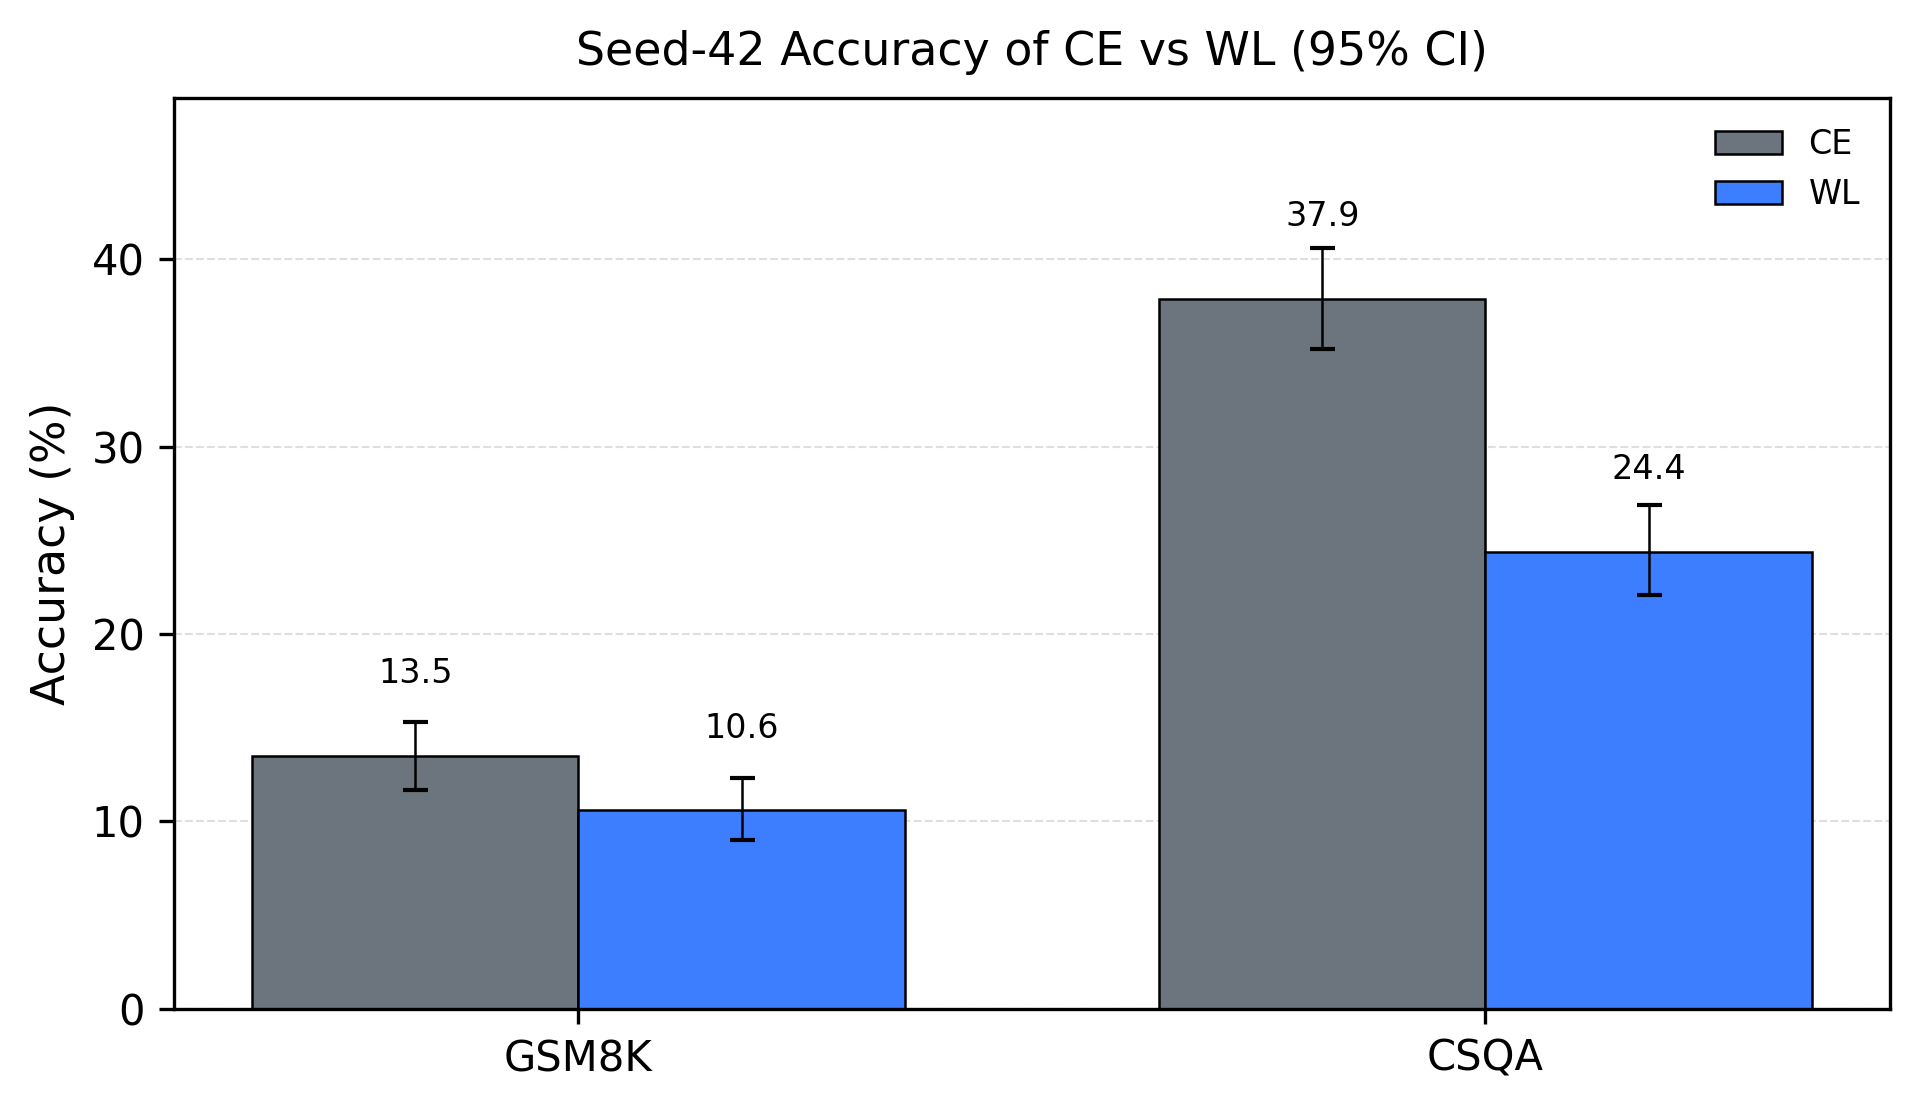

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ---- Data ----
datasets = ["GSM8K", "CSQA"]
CE = np.array([13.5, 37.9])
WL = np.array([10.6, 24.4])

# 95% CIs (asymmetric)
CE_err = np.array([[1.8, 2.7],
                   [1.8, 2.7]])
WL_err = np.array([[1.6, 2.3],
                   [1.7, 2.5]])

# ---- Figure ----
plt.figure(figsize=(6.5, 3.8), dpi=300)

x = np.arange(len(datasets))
width = 0.36
ce_color = "#6C757D"
wl_color = "#3D7DFF"

ce_bars = plt.bar(x - width/2, CE, width, label="CE", color=ce_color,
                  yerr=CE_err, capsize=3, edgecolor="black", linewidth=0.6,
                  error_kw=dict(lw=0.6))
wl_bars = plt.bar(x + width/2, WL, width, label="WL", color=wl_color,
                  yerr=WL_err, capsize=3, edgecolor="black", linewidth=0.6,
                  error_kw=dict(lw=0.6))

# ---- Add numeric labels (minimal style) ----
def add_labels(bars):
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h + 3.5, f"{h:.1f}",
                 ha="center", va="bottom", fontsize=8)

add_labels(ce_bars)
add_labels(wl_bars)

# ---- Axes/labels ----
plt.xticks(x, datasets, fontsize=10)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.ylim(0, max(CE.max() + CE_err[1].max(), WL.max() + WL_err[1].max()) + 8)

# Title (short, professional)
plt.title("Seed-42 Accuracy of CE vs WL (95% CI)", fontsize=11, pad=8)

# Minimal grid
plt.gca().yaxis.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)
plt.gca().set_axisbelow(True)
plt.gca().set_facecolor("white")
plt.gcf().set_facecolor("white")

# Legend (smaller, no box)
plt.legend(frameon=False, fontsize=8, loc="upper right")

plt.tight_layout()

# ---- Save safely ----
outdir = "./"  # or "/kaggle/working/"
os.makedirs(outdir, exist_ok=True)
png_path = os.path.join(outdir, "ce_vs_wl_seed42_clean.png")
pdf_path = os.path.join(outdir, "ce_vs_wl_seed42_clean.pdf")

plt.savefig(png_path, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")

print("Saved to:", png_path, pdf_path)


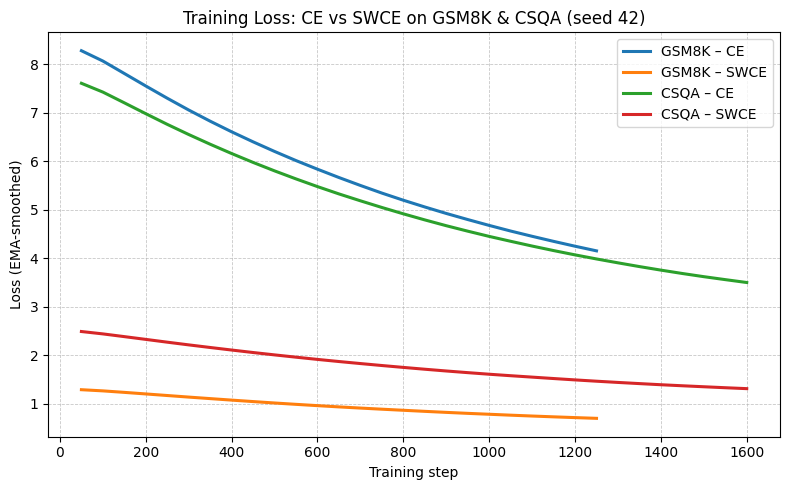

In [11]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt

#path
GSM8K_CE_LOG   = ""
GSM8K_SWCE_LOG = ""
CSQA_CE_LOG    = ""
CSQA_SWCE_LOG  = ""


RUNS = [
    ("GSM8K – CE",   GSM8K_CE_LOG),
    ("GSM8K – SWCE", GSM8K_SWCE_LOG),
    ("CSQA – CE",    CSQA_CE_LOG),
    ("CSQA – SWCE",  CSQA_SWCE_LOG),
]

EMA_SPAN = 40   
LINEWIDTH = 2.2
FIG_DPI = 240


def load_log_file(file_path: str) -> pd.DataFrame | None:
    """Load log_history.json (file path) and return a DataFrame with step + smoothed loss."""
    if not (isinstance(file_path, str) and os.path.isfile(file_path)):
        return None

    with open(file_path, "r") as f:
        data = json.load(f)

    if not isinstance(data, list) or len(data) == 0:
        return None

    df = pd.DataFrame(data)

    # Ensure 'step'
    if "step" not in df.columns:
        df["step"] = range(len(df))

    # Which loss column to use
    loss_col = None
    if "loss" in df.columns:            # training loss
        loss_col = "loss"
    elif "eval_loss" in df.columns:     # fallback to eval_loss if training loss not logged
        loss_col = "eval_loss"
    else:
        return None

    df = df[["step", loss_col]].copy()
    df.columns = ["step", "loss"]  # unify column name
    df["step"] = pd.to_numeric(df["step"], errors="coerce")
    df["loss"] = pd.to_numeric(df["loss"], errors="coerce")
    df = df.dropna(subset=["step", "loss"]).sort_values("step").reset_index(drop=True)

    if df.empty:
        return None

    # Exponential Moving Average smoothing
    df["loss_smooth"] = df["loss"].ewm(span=EMA_SPAN, adjust=False).mean()
    return df



plt.figure(figsize=(8, 5))
lines_plotted = 0
missing = []

for label, path in RUNS:
    df = load_log_file(path)
    if df is None or df.empty:
        missing.append(label)
        continue
    plt.plot(df["step"], df["loss_smooth"], linewidth=LINEWIDTH, label=label)
    lines_plotted += 1

if lines_plotted == 0:
    raise RuntimeError("No valid curves found. Check that the file paths are correct.")

plt.title("Training Loss: CE vs SWCE on GSM8K & CSQA (seed 42)")
plt.xlabel("Training step")
plt.ylabel("Loss (EMA-smoothed)")
'''plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("ce_vs_swce_loss_comparison_seed42.png", dpi=FIG_DPI)
plt.show()'''
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("ce_vs_swce_loss_comparison_seed42.png", dpi=FIG_DPI)
plt.show()


# Optional: print which runs were missing
if missing:
    print("Not plotted (missing or malformed logs): " + ", ".join(missing))
